## Setup

In [13]:
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig2_path = "/content/drive/My Drive/fig2_neet_type_by_age_sex.png"  # where the stacked bar chart is saved on Drive

## Mount Google Drive

In [14]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the data

In [15]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Table 2: 2026 NEET rates by age group and sex

In [16]:
age_groups = ["16-19", "20-24", "25-29"]  # age groups, in order
row_order = [(age, sex) for age in age_groups for sex in ["Men", "Women"]]  # the six rows: Men before Women in each age group

age_vars = {"16-19": "age16_19", "20-24": "age20_24", "25-29": "age25_29"}  # age-group dummies from the cleaned data
sex_values = {"Men": 0, "Women": 1}  # female = 0 for Men, 1 for Women

def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

df26 = df[df["year"] == 2026].copy()  # keep only the 2026 survey
known = df26.dropna(subset=["neet"])  # keep only people whose neet is known

rows = {}  # weighted rates, one row per age group and sex
counts = {}  # unweighted respondents, one per row
for age, sex in row_order:  # loop over the six rows
    group = known[(known[age_vars[age]] == 1) & (known["female"] == sex_values[sex])]  # people in this row
    rows[f"{age} {sex}"] = {  # row label, e.g. "16-19 Men"
        "Unemployed NEET (%)": wmean(group, "unemployed_neet") * 100,  # weighted percent unemployed NEET
        "Out-of-labor-force NEET (%)": wmean(group, "nilf_neet") * 100,  # weighted percent out-of-labor-force NEET
        "Total NEET (%)": wmean(group, "neet") * 100,  # weighted percent NEET
    }  # end of one row
    counts[f"{age} {sex}"] = len(group)  # unweighted respondents in this row

table = pd.DataFrame(rows).T  # dictionary -> table, one row per age group and sex
people = pd.Series(counts)  # unweighted respondents, same row labels

gap = (table["Unemployed NEET (%)"] + table["Out-of-labor-force NEET (%)"] - table["Total NEET (%)"]).abs()  # difference in each row, before rounding
print("Table 2. NEET rates in 2026, % of people (weighted with asecwt). Rows: age group and sex.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal
print()  # empty line
print("Check: unemployed NEET + out-of-labor-force NEET = total NEET in every row:", bool((gap < 1e-9).all()))  # True or False
print("Largest difference in any row (before rounding):", gap.max())  # should be about 0
print()  # empty line
print("Unweighted number of respondents in each row (neet not missing).")  # counts title
print(people.to_string())  # counts, whole numbers

Table 2. NEET rates in 2026, % of people (weighted with asecwt). Rows: age group and sex.
             Unemployed NEET (%)  Out-of-labor-force NEET (%)  Total NEET (%)
16-19 Men                    2.3                          5.9             8.2
16-19 Women                  1.5                          5.0             6.5
20-24 Men                    5.0                          8.7            13.7
20-24 Women                  3.5                         12.4            15.9
25-29 Men                    5.2                          7.7            12.9
25-29 Women                  3.2                         16.9            20.0

Check: unemployed NEET + out-of-labor-force NEET = total NEET in every row: True
Largest difference in any row (before rounding): 1.7763568394002505e-15

Unweighted number of respondents in each row (neet not missing).
16-19 Men      3835
16-19 Women    3575
20-24 Men      3513
20-24 Women    3400
25-29 Men      3630
25-29 Women    3709


**What one cell means.** Take the row "20-24 Women" and the column "Unemployed NEET (%)". Among women aged 20-24 in the 2026 survey whose NEET status is known, the cell is the percent who were NEET and unemployed: not employed, looking for work, and not in school. The column "Out-of-labor-force NEET (%)" is the percent who were NEET and not looking for work. The column "Total NEET (%)" is the percent who were NEET, which is the first two columns added together. People are counted by how many people in the country they represent (`asecwt`), so each number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people. The counts under the table show how many survey respondents sit behind each row.

## Figure 2: 2026 NEET rates by age group and sex

Table 2. NEET rates in 2026, % of people (weighted with asecwt). Figure 2 shows this table.
             Unemployed NEET (%)  Out-of-labor-force NEET (%)  Total NEET (%)
16-19 Men                    2.3                          5.9             8.2
16-19 Women                  1.5                          5.0             6.5
20-24 Men                    5.0                          8.7            13.7
20-24 Women                  3.5                         12.4            15.9
25-29 Men                    5.2                          7.7            12.9
25-29 Women                  3.2                         16.9            20.0


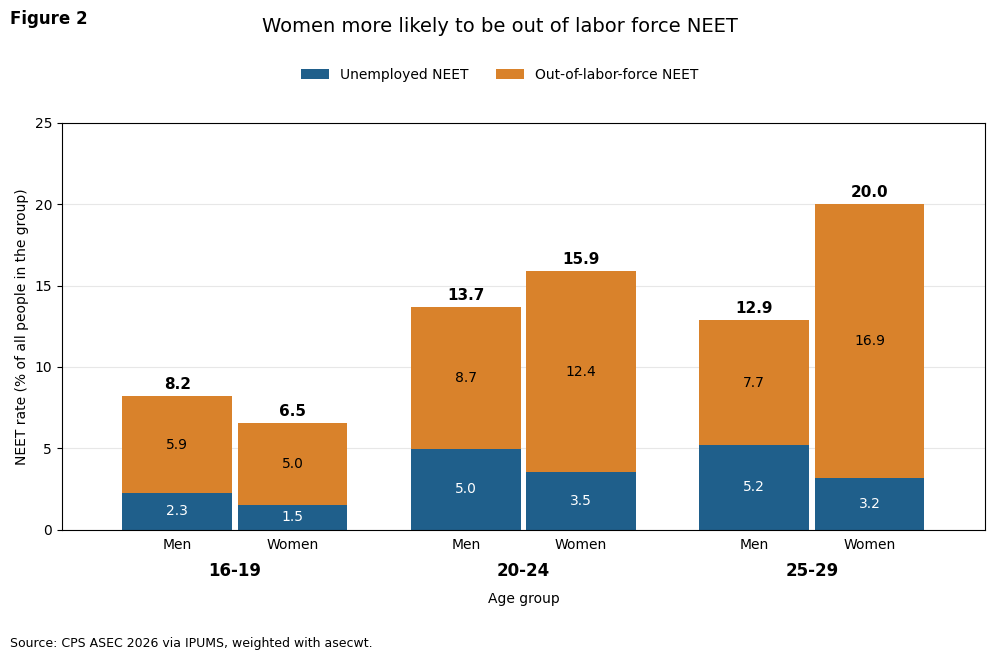

In [18]:
chart_title = "Women more likely to be out of labor force NEET"  # chart title: replace this text with your own sentence

print("Table 2. NEET rates in 2026, % of people (weighted with asecwt). Figure 2 shows this table.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal

age_groups = ["16-19", "20-24", "25-29"]  # one group of bars per age group
colors = ["#1f5f8b", "#d9822b"]  # unemployed NEET (bottom), out-of-labor-force NEET (top)
text_colors = ["white", "black"]  # number color inside each segment
ymax = int(table["Total NEET (%)"].max() * 1.15 / 5) * 5 + 5  # round number above the tallest bar, with room for its label

fig, ax = plt.subplots(figsize=(10, 6.5))  # one chart
for g, age in enumerate(age_groups):  # loop over the three age groups
    for offset, sex in [(-0.2, "Men"), (0.2, "Women")]:  # Men first, then Women, side by side
        x = g + offset  # position of this bar
        row = table.loc[f"{age} {sex}"]  # numbers for this bar
        unemp = row["Unemployed NEET (%)"]  # bottom segment
        nilf = row["Out-of-labor-force NEET (%)"]  # top segment
        total = row["Total NEET (%)"]  # full height of the bar
        ax.bar(x, unemp, width=0.38, color=colors[0], label="Unemployed NEET" if g == 0 and sex == "Men" else None)  # bottom segment
        ax.bar(x, nilf, width=0.38, bottom=unemp, color=colors[1], label="Out-of-labor-force NEET" if g == 0 and sex == "Men" else None)  # top segment
        ax.text(x, unemp / 2, f"{unemp:.1f}", ha="center", va="center", color=text_colors[0], fontsize=10)  # value inside bottom segment
        ax.text(x, unemp + nilf / 2, f"{nilf:.1f}", ha="center", va="center", color=text_colors[1], fontsize=10)  # value inside top segment
        ax.text(x, total + ymax * 0.01, f"{total:.1f}", ha="center", va="bottom", fontsize=11, fontweight="bold")  # total above the bar
        ax.text(x, -ymax * 0.02, sex, ha="center", va="top", fontsize=10)  # Men or Women under the bar
    ax.text(g, -ymax * 0.08, age, ha="center", va="top", fontsize=12, fontweight="bold")  # age group under its two bars

ax.set_xticks([])  # no default x ticks, the labels above are used instead
ax.set_xlim(-0.6, 2.6)  # room on both sides
ax.set_xlabel("Age group", labelpad=45)  # x-axis label, pushed below the age groups
ax.set_ylabel("NEET rate (% of all people in the group)")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
ax.set_axisbelow(True)  # grid lines behind the bars

handles, labels = ax.get_legend_handles_labels()  # the two NEET types
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 2", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.05, 1, 0.9])  # leave room for the title, legend and note
fig.text(0.01, 0.01, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.savefig(fig2_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:
Finding: